# Assembly-line balancing

A small factory builds electric bicycles on a paced line. The frame moves to the next station every
102 seconds, so no station can hold more than 102 seconds of work. Building one bicycle takes 30
tasks, and many of them can only start after others are done: the wheel goes on before the chain,
the harness before the controller. Every station is a workspace and a person to pay. The question
is **which task goes to which station, so that the line needs as few stations as possible**.

In this notebook you will:

1. describe the tasks and their order as Python objects,
2. solve it and draw every station against the cycle time, and the task graph by station,
3. check the result yourself, without trusting the solver's score,
4. add a rule that shares the work evenly across the stations,
5. change the line speed and see what each speed costs in stations,
6. restart from a running line after a design change, with a task pinned to its station.

Requires Python 3.11+: `pip install optimaru matplotlib`

In [1]:
import itertools
import math

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import ListedColormap

from optimaru import assembly_line_balancing as alb
from optimaru.assembly_line_balancing import constraints as rules
from optimaru.assembly_line_balancing.models import (
    AssemblyLineBalancingProblemModel, PrecedenceModel, TaskGroupModel, TaskModel, TaskPairModel,
)

COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, MUTED = "#52514e", "#898781"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "xtick.color": MUTED, "ytick.color": MUTED,
    "grid.color": "#e1e0d9", "grid.linewidth": 0.8, "legend.frameon": False, "font.size": 10,
})

## 1. Describe the bicycle

Everything is a pydantic model, and `station` on each task is what the solver fills in.

| Object | What it holds |
| --- | --- |
| `TaskModel` | one task: `id`, `duration`, and optional `min_station`, `max_station`, `fixed_station`, `forbidden_stations` |
| `PrecedenceModel` | one order rule: `before` must not sit at a later station than `after` |
| `TaskGroupModel`, `TaskPairModel` | tasks that must share a station, and pairs that must not |
| `AssemblyLineBalancingProblemModel` | `cycle_time`, the `tasks`, `precedences`, and the two zoning lists |

Tasks in one order rule may share a station, since one person can do them in sequence. Durations
are integers in any unit, here seconds.

Here is the fictional bicycle: each task with its seconds and the tasks it waits for. Two zoning
rules apply. Both brakes are bled with the same kit, so they share a station, and the battery is
never fitted where the harness is being worked on.

In [2]:
TASKS = [
    ("Frame jig", 28, []),
    ("Headset", 24, ["Frame jig"]),
    ("Bottom bracket", 32, ["Frame jig"]),
    ("Motor mount", 46, ["Bottom bracket"]),
    ("Fork", 30, ["Headset"]),
    ("Stem and bars", 22, ["Fork"]),
    ("Brake levers", 14, ["Stem and bars"]),
    ("Shifter", 12, ["Stem and bars"]),
    ("Display", 16, ["Stem and bars"]),
    ("Rear wheel", 34, ["Motor mount"]),
    ("Front wheel", 26, ["Fork"]),
    ("Crank", 24, ["Bottom bracket"]),
    ("Chain", 20, ["Rear wheel", "Crank"]),
    ("Derailleur", 28, ["Rear wheel"]),
    ("Brake front", 26, ["Front wheel", "Brake levers"]),
    ("Brake rear", 26, ["Rear wheel", "Brake levers"]),
    ("Shift cable", 22, ["Shifter", "Derailleur"]),
    ("Battery rail", 18, ["Frame jig"]),
    ("Harness", 40, ["Motor mount", "Display", "Battery rail"]),
    ("Controller", 30, ["Harness"]),
    ("Battery", 14, ["Battery rail", "Controller"]),
    ("Saddle", 10, ["Frame jig"]),
    ("Pedals", 8, ["Crank"]),
    ("Lights", 18, ["Harness"]),
    ("Fenders", 24, ["Rear wheel", "Front wheel"]),
    ("Rack", 20, ["Rear wheel"]),
    ("Tune", 38, ["Chain", "Shift cable", "Brake front", "Brake rear"]),
    ("Firmware", 16, ["Controller", "Battery"]),
    ("Test ride", 30, ["Tune", "Firmware"]),
    ("Pack", 22, ["Test ride", "Pedals", "Saddle", "Lights", "Fenders", "Rack"]),
]
CYCLE_TIME = 102


def make_problem(cycle_time=CYCLE_TIME, extra_seconds=None):
    """A fresh, unsolved line. The solver works in place, so each experiment gets its own."""
    extra_seconds = extra_seconds or {}
    return AssemblyLineBalancingProblemModel(
        cycle_time=cycle_time,
        tasks=[TaskModel(id=name, duration=seconds + extra_seconds.get(name, 0)) for name, seconds, _ in TASKS],
        precedences=[
            PrecedenceModel(before=earlier, after=name) for name, _, waits_for in TASKS for earlier in waits_for
        ],
        same_station_groups=[TaskGroupModel(id="Bleed kit", task_ids=["Brake front", "Brake rear"])],
        different_station_pairs=[TaskPairModel(first="Harness", second="Battery")],
    )


def lower_bound(problem):
    """The fewest stations that could hold the total work at this cycle time."""
    return math.ceil(sum(task.duration for task in problem.tasks) / problem.cycle_time)


problem = make_problem()
total_work = sum(task.duration for task in problem.tasks)
print(f"{len(problem.tasks)} tasks, {len(problem.precedences)} order rules, {total_work} s of work per bicycle")
print(f"cycle time {problem.cycle_time} s, so at least {lower_bound(problem)} stations")

30 tasks, 47 order rules, 718 s of work per bicycle
cycle time 102 s, so at least 8 stations


Here are the order rules as a graph, read from left to right. Each arrow means "must not come after".

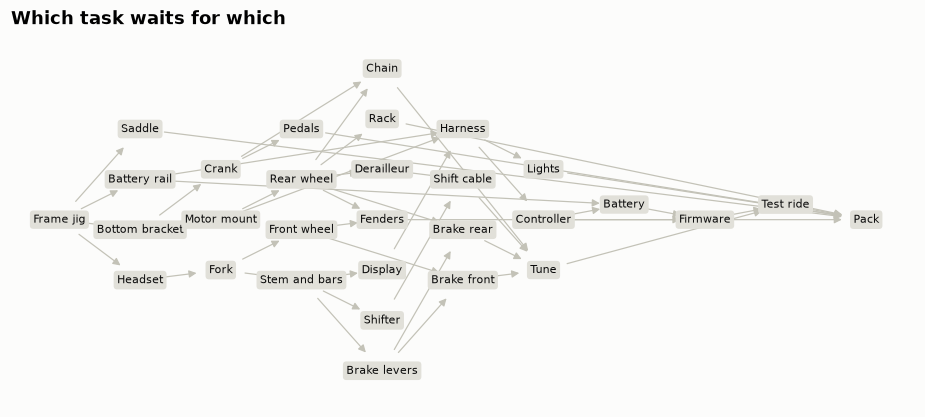

In [3]:
def layout(problem):
    """Columns by longest chain of predecessors, each column ordered to keep arrows short."""
    waits_for = {task.id: [] for task in problem.tasks}
    for edge in problem.precedences:
        waits_for[edge.after].append(edge.before)
    depth = {}
    for task in problem.tasks:  # TASKS lists every task after the tasks it waits for
        depth[task.id] = 1 + max((depth[earlier] for earlier in waits_for[task.id]), default=-1)
    position = {}
    for column in range(max(depth.values()) + 1):
        names = [name for name in depth if depth[name] == column]
        anchor = {
            name: np.mean([position[earlier][1] for earlier in waits_for[name]]) if waits_for[name] else 0
            for name in names
        }
        names.sort(key=lambda name: anchor[name])
        for row, name in enumerate(names):
            position[name] = (column, row - (len(names) - 1) / 2 + 0.3 * (column % 2))
    return position


WHITE_TEXT = {COLORS[0], COLORS[5], COLORS[6], COLORS[7]}


def draw_graph(ax, problem, color_of):
    position = layout(problem)
    for edge in problem.precedences:
        ax.annotate("", xy=position[edge.after], xytext=position[edge.before], arrowprops={
            "arrowstyle": "-|>", "color": "#c3c2b7", "linewidth": 0.8, "shrinkA": 16, "shrinkB": 16,
        })
    for name, (x, y) in position.items():
        fill = color_of(name)
        ax.text(x, y, name, ha="center", va="center", fontsize=7.5,
                color="white" if fill in WHITE_TEXT else "#0b0b0b",
                bbox={"boxstyle": "round,pad=0.3", "facecolor": fill, "edgecolor": "none"})
    columns = max(x for x, _ in position.values())
    rows = max(abs(y) for _, y in position.values())
    ax.set(xlim=(-0.6, columns + 0.6), ylim=(-rows - 0.7, rows + 0.7))
    ax.axis("off")


fig, ax = plt.subplots(figsize=(10.6, 4.4))
draw_graph(ax, problem, lambda name: "#e1e0d9")
ax.set_title("Which task waits for which", loc="left")
plt.show()

## 2. Solve it

`alb.solve` fills in `station` on each task, plus `stations_used`, `station_loads`, `score_hard` and
`score_soft`, and returns the score. This use case has no compiled core: it runs a simulated
annealing written in Python, starting from a pass that fills stations in order of the task graph.
The search stops at `time_limit_seconds` or after `SolverConfig.max_iterations` steps, 50,000 by
default, whichever comes first.

The score has two levels, compared in order:

- **hard**: minus the seconds over the cycle time, the order rules reversed and the zoning rules
  broken, where `0` means the line works
- **soft**: minus the number of stations with work on them

Station numbers are labels on a line and can skip: an empty number costs nothing and does not count.
The helper below renumbers the stations in use from 1, in line order.

In [4]:
def stations(problem):
    """The tasks of each station in use, in line order."""
    groups = {}
    for task in problem.tasks:
        groups.setdefault(task.station, []).append(task)
    return [groups[number] for number in sorted(groups)]


score = alb.solve(problem, time_limit_seconds=5, random_seed=42)

print("score   :", score)
print("stations:", problem.stations_used)
bound = lower_bound(problem)
if score[0] == 0 and problem.stations_used == bound:
    print(f"this equals the lower bound of {bound}, so no line at this cycle time uses fewer stations")
else:
    print(f"lower bound is {bound}, so this is the best found in the time limit, not a proven minimum")

score   : (0, -8.0)
stations: 8
this equals the lower bound of 8, so no line at this cycle time uses fewer stations


### Station by station

Each row is a station and each block a task, in the order the worker does them. The black line is
the cycle time. The gap between a bar and the line is the time that worker stands idle on every
bicycle.

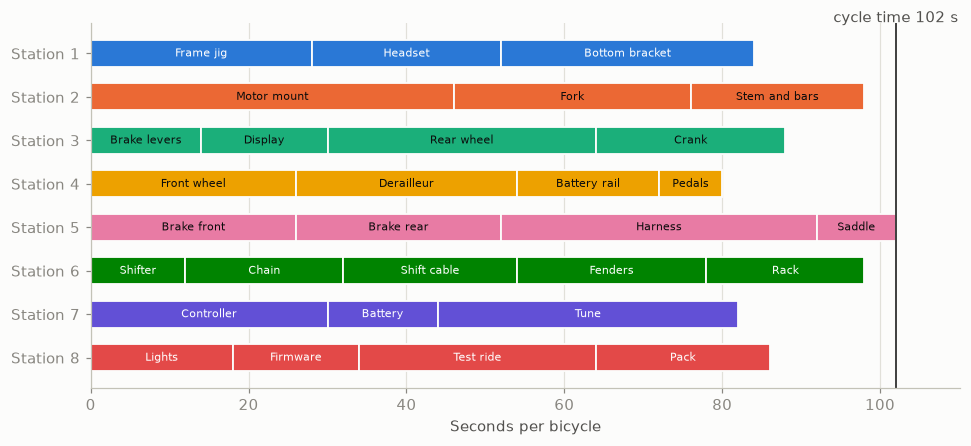

In [5]:
def station_color(problem):
    """Task name to color, by position along the line."""
    return {task.id: COLORS[position] for position, group in enumerate(stations(problem)) for task in group}


colors = station_color(problem)
fig, ax = plt.subplots(figsize=(10.2, 4.3))
for row, group in enumerate(stations(problem)):
    start = 0
    fill = colors[group[0].id]
    for task in group:
        ax.barh(row, task.duration, left=start, height=0.62, color=fill, edgecolor="#fcfcfb", linewidth=1.2)
        ax.text(start + task.duration / 2, row, task.id, ha="center", va="center", fontsize=7.5,
                color="white" if fill in WHITE_TEXT else "#0b0b0b")
        start += task.duration
ax.axvline(problem.cycle_time, color="#0b0b0b", linewidth=1)
ax.text(problem.cycle_time, -0.72, f"cycle time {problem.cycle_time} s", ha="center", color=INK)
ax.set_yticks(range(problem.stations_used), [f"Station {row + 1}" for row in range(problem.stations_used)])
ax.invert_yaxis()
ax.set(xlabel="Seconds per bicycle", xlim=(0, problem.cycle_time * 1.08))
ax.grid(True, axis="x")
plt.show()

### The task graph by station

The same assignment on the graph from section 1, with the same station colors. Colors running from
left to right without doubling back are the order rules at work.

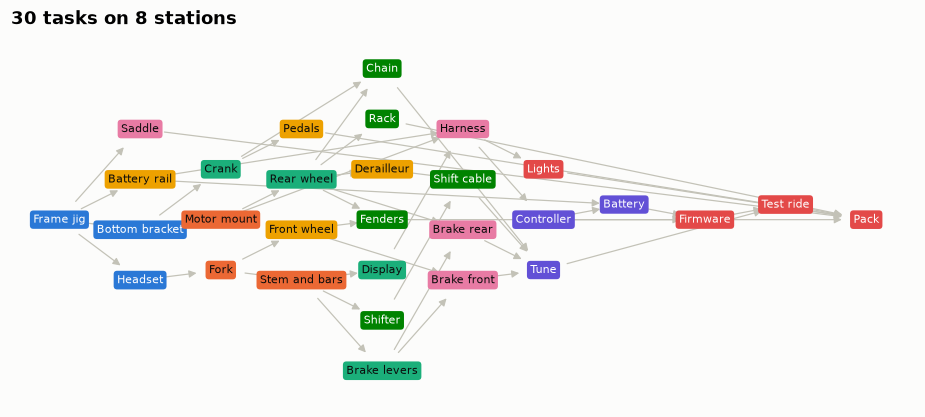

In [6]:
fig, ax = plt.subplots(figsize=(10.6, 4.4))
draw_graph(ax, problem, lambda name: colors[name])
ax.set_title(f"{len(problem.tasks)} tasks on {problem.stations_used} stations", loc="left")
plt.show()

## 3. Check the result yourself

The answer is one station number per task, so it can be verified with no solver code.

In [7]:
station_of = {task.id: task.station for task in problem.tasks}
duration_of = {task.id: task.duration for task in problem.tasks}

loads = {}
for name, number in station_of.items():
    loads[number] = loads.get(number, 0) + duration_of[name]

print("every task placed     :", all(number >= 0 for number in station_of.values()))
print("longest station       :", max(loads.values()), "of", problem.cycle_time)
print("over the cycle time   :", [number for number, load in loads.items() if load > problem.cycle_time])
print("order rules reversed  :", [
    (edge.before, edge.after) for edge in problem.precedences if station_of[edge.before] > station_of[edge.after]
])
print("brakes share a station:", station_of["Brake front"] == station_of["Brake rear"])
print("battery away from harness:", station_of["Battery"] != station_of["Harness"])

used = sum(loads.values())
print(f"line busy {100 * used / (len(loads) * problem.cycle_time):.1f}% of the time")

every task placed     : True
longest station       : 102 of 102
over the cycle time   : []
order rules reversed  : []
brakes share a station: True
battery away from harness: True
line busy 88.0% of the time


## 4. Change the rules, not the solver

Every rule is a plugin. `list_constraints()` shows what ships with this use case, and the
`constraints` argument takes the list you want. Only listed constraints are scored. `weight` scales
a rule, `hard` moves it between levels, and `exponent` shapes large violations.

The default rules count stations and nothing else, so one worker can be flat out while another
waits. `workload_balance` scores the gap between the busiest and the quietest station, and it ships
with weight 0, which means it is off. Weight 0.1 says that ten seconds of gap are worth one station,
so the search may spend a station if that evens out the line.

station_capacity
task_precedence
station_count_limit
task_station_bounds
fixed_task_stations
forbidden_task_stations
same_station_groups
different_station_pairs
minimize_stations
workload_balance


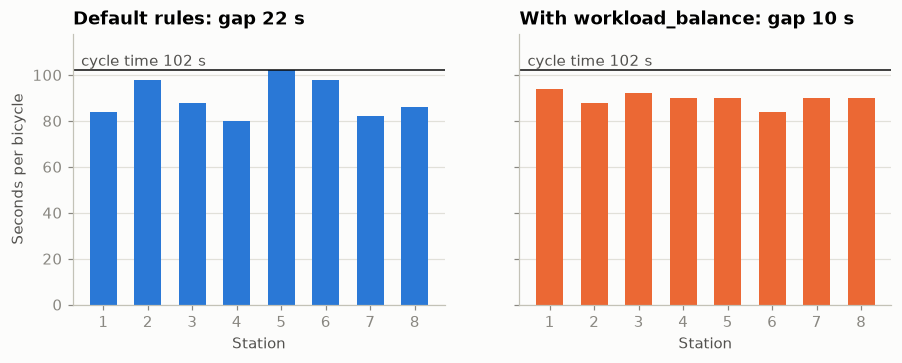

default rules : 8 stations, gap 22 s, loads [84, 98, 88, 80, 102, 98, 82, 86]
balanced      : 8 stations, gap 10 s, loads [94, 88, 92, 90, 90, 84, 90, 90]
balanced score: (0, -9.0)


In [8]:
for name in alb.list_constraints():
    print(name)

balanced_rules = [rule for rule in rules.DEFAULTS if rule.name != "workload_balance"]
balanced_rules.append(rules.WorkloadBalance(weight=0.1))

balanced = make_problem()
balanced_score = alb.solve(balanced, time_limit_seconds=5, random_seed=1, constraints=balanced_rules)


def station_loads(problem):
    return [sum(task.duration for task in group) for group in stations(problem)]


def gap(problem):
    return max(station_loads(problem)) - min(station_loads(problem))


fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.2), sharey=True)
for ax, plan, color, label in zip(axes, [problem, balanced], COLORS, ["Default rules", "With workload_balance"]):
    load = station_loads(plan)
    ax.bar(range(1, len(load) + 1), load, width=0.6, color=color)
    ax.axhline(plan.cycle_time, color="#0b0b0b", linewidth=1)
    ax.text(0.5, plan.cycle_time + 2, f"cycle time {plan.cycle_time} s", color=INK)
    ax.set_xticks(range(1, len(load) + 1))
    ax.set(title=f"{label}: gap {gap(plan)} s", xlabel="Station", ylim=(0, 118))
    ax.grid(True, axis="y")
axes[0].set_ylabel("Seconds per bicycle")
plt.show()

print(f"default rules : {problem.stations_used} stations, gap {gap(problem)} s, loads {station_loads(problem)}")
print(f"balanced      : {balanced.stations_used} stations, gap {gap(balanced)} s, loads {station_loads(balanced)}")
print(f"balanced score: {balanced_score}")

## 5. What does line speed cost?

A shorter cycle makes more bicycles per shift, and it needs more stations. Here the same bicycle is
solved for a range of cycle times. The lower bound is the same formula as in section 1, and the
table turns each cycle time into bicycles per eight-hour shift.

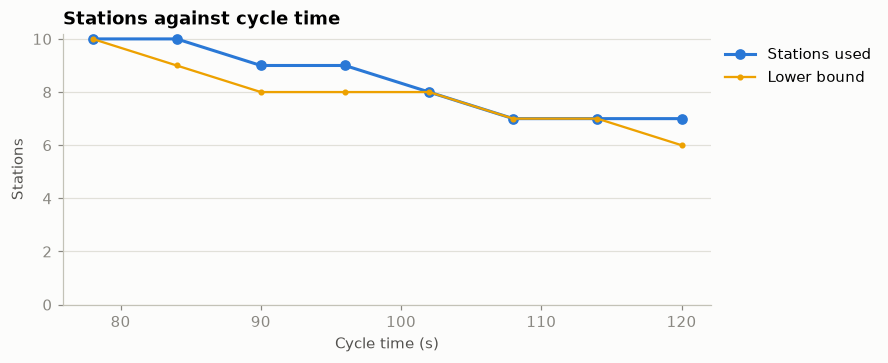

cycle  78 s: 369 bicycles per shift, 10 stations (bound 10), line busy 92.1%
cycle  84 s: 342 bicycles per shift, 10 stations (bound 9), line busy 85.5%
cycle  90 s: 320 bicycles per shift,  9 stations (bound 8), line busy 88.6%
cycle  96 s: 300 bicycles per shift,  9 stations (bound 8), line busy 83.1%
cycle 102 s: 282 bicycles per shift,  8 stations (bound 8), line busy 88.0%
cycle 108 s: 266 bicycles per shift,  7 stations (bound 7), line busy 95.0%
cycle 114 s: 252 bicycles per shift,  7 stations (bound 7), line busy 90.0%
cycle 120 s: 240 bicycles per shift,  7 stations (bound 6), line busy 85.5%


In [9]:
SHIFT_SECONDS = 8 * 3600
cycle_times = list(range(78, 126, 6))
needed, bounds = [], []
for cycle_time in cycle_times:
    candidate = make_problem(cycle_time)
    candidate_score = alb.solve(candidate, time_limit_seconds=5, random_seed=42)
    assert candidate_score[0] == 0, f"no feasible line found at cycle time {cycle_time}"
    needed.append(candidate.stations_used)
    bounds.append(lower_bound(candidate))

fig, ax = plt.subplots(figsize=(7.6, 3.2))
ax.plot(cycle_times, needed, color=COLORS[0], linewidth=2, marker="o", markersize=6, label="Stations used")
ax.plot(cycle_times, bounds, color=COLORS[3], linewidth=1.5, marker="o", markersize=3, label="Lower bound")
ax.set(title="Stations against cycle time", xlabel="Cycle time (s)", ylabel="Stations", ylim=(0, None))
ax.grid(True, axis="y")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

for cycle_time, count, floor in zip(cycle_times, needed, bounds):
    print(f"cycle {cycle_time:3d} s: {SHIFT_SECONDS // cycle_time:3d} bicycles per shift, {count:2d} stations "
          f"(bound {floor}), line busy {100 * total_work / (count * cycle_time):.1f}%")

Stations come in whole numbers, so the count moves in steps, and the bound moves with the total
work divided by the cycle. Where the count stays put while the cycle grows, the extra seconds become
idle time: look at the last column. The useful cycle times are the shortest ones at each station
count.

## 6. Restart from a running line

`with_initial_solution` starts the search from a solved model, or the same thing as a JSON dict,
instead of from the construction pass. `max_iterations=0` runs the construction only.

**Change `random_seed` between rounds.** A round that finds nothing new leaves the plan as it was,
so with the same seed the next round starts from the same plan with the same random numbers,
repeats the same steps and finds nothing again. The grid shows runs of short rounds, 1,000 steps
each, from the same construction plan.

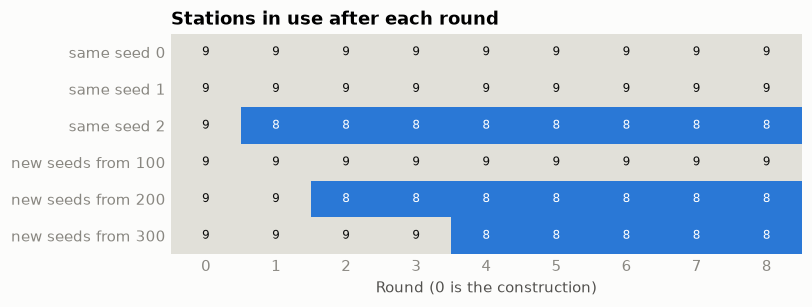

In [10]:
def run_rounds(seeds, steps=1000):
    """Stations in use after each short round, every round continuing from the previous plan."""
    plan = make_problem()
    alb.solve(plan, config=alb.SolverConfig(max_iterations=0))
    history = [plan.stations_used]
    for seed in seeds:
        warm = alb.with_initial_solution(make_problem(), plan)
        alb.solve(warm, config=alb.SolverConfig(max_iterations=steps, random_seed=seed))
        plan = warm
        history.append(plan.stations_used)
    return history


ROUNDS = 8
runs = {f"same seed {seed}": run_rounds([seed] * ROUNDS) for seed in range(3)}
runs |= {f"new seeds from {first}": run_rounds(range(first, first + ROUNDS)) for first in (100, 200, 300)}

grid = np.array(list(runs.values()))
fig, ax = plt.subplots(figsize=(7.4, 2.6))
ax.imshow(grid == grid.min(), cmap=ListedColormap(["#e1e0d9", "#2a78d6"]), aspect="auto", vmin=0, vmax=1)
for (row, column), value in np.ndenumerate(grid):
    ax.text(column, row, str(value), ha="center", va="center", fontsize=8,
            color="white" if value == grid.min() else "#0b0b0b")
ax.set_yticks(range(len(runs)), list(runs))
ax.set_xticks(range(ROUNDS + 1))
ax.set(title="Stations in use after each round", xlabel="Round (0 is the construction)")
ax.spines[["left", "bottom"]].set_visible(False)
ax.tick_params(length=0)
plt.show()

A row can stop changing for three different reasons. In a same-seed row above the bound, each round
repeats the last, so it will never move. A new-seed row above the bound has not found the improvement
yet, and each further round is a fresh attempt. A row at the lower bound has nothing left to find,
since the soft level cannot improve past it.

### After a design change

Engineering adds 12 seconds to the harness, which pushes its station past the cycle time. The motor
mount press is bolted to the floor, so `fixed_station` pins that task where it is, as a hard rule.

Starting from the running line sounds as if it would keep the line as it is, but the score has no
term for change. While the search repairs the overload it accepts every step that leaves the score
equal, so tasks drift. The fix is to say what may not move: this run also pins every task outside
the harness station and its two neighbours.

To compare the three approaches, count the pairs of tasks that shared a station before and still
do. That count does not depend on station numbers, which a fresh solve changes anyway.

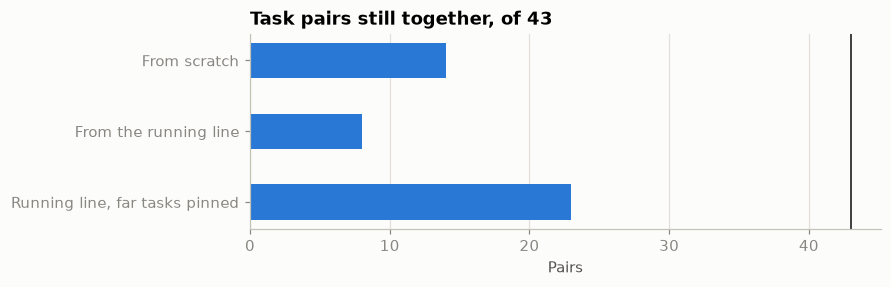

old plan under the new times: hard -12
From scratch                   : score 0 / -8.0, 8 stations, 14 pairs kept, 1 tasks pinned
From the running line          : score 0 / -8.0, 8 stations, 8 pairs kept, 1 tasks pinned
Running line, far tasks pinned : score 0 / -8.0, 8 stations, 23 pairs kept, 17 tasks pinned


In [11]:
def station_mates(problem):
    return {
        pair for group in stations(problem) for pair in itertools.combinations(sorted(t.id for t in group), 2)
    }


line_position = {task.id: position for position, group in enumerate(stations(problem)) for task in group}


def changed_problem(free_stations_around_harness=None):
    """The longer harness, with the motor mount pinned and optionally the far end of the line too."""
    changed = make_problem(extra_seconds={"Harness": 12})
    for task in changed.tasks:
        distance = abs(line_position[task.id] - line_position["Harness"])
        far_away = free_stations_around_harness is not None and distance > free_stations_around_harness
        if task.id == "Motor mount" or far_away:
            task.fixed_station = station_of[task.id]
    return changed


hard_before = alb.calculate_score(alb.with_initial_solution(changed_problem(), problem))[0]

cold = changed_problem()
warm = alb.with_initial_solution(changed_problem(), problem)
pinned = alb.with_initial_solution(changed_problem(free_stations_around_harness=1), problem)
plans = {"From scratch": cold, "From the running line": warm, "Running line, far tasks pinned": pinned}
for plan in plans.values():
    alb.solve(plan, time_limit_seconds=5, random_seed=2)

before = station_mates(problem)
kept = {label: len(before & station_mates(plan)) for label, plan in plans.items()}

fig, ax = plt.subplots(figsize=(7.4, 2.3))
ax.barh(list(kept), list(kept.values()), height=0.5, color=COLORS[0])
ax.axvline(len(before), color="#0b0b0b", linewidth=1)
ax.invert_yaxis()
ax.set(title=f"Task pairs still together, of {len(before)}", xlabel="Pairs", xlim=(0, len(before) * 1.05))
ax.grid(True, axis="x")
plt.show()

print(f"old plan under the new times: hard {hard_before}")
for label, plan in plans.items():
    pins = sum(task.fixed_station is not None for task in plan.tasks)
    print(f"{label:31s}: score {plan.score_hard} / {plan.score_soft}, {plan.stations_used} stations, "
          f"{kept[label]} pairs kept, {pins} tasks pinned")

Pin only what truly cannot move: pin too much and no feasible line is left. `fixed_station` is an
absolute station number, and so are `min_station`, `max_station`, `forbidden_stations` and
`max_stations`. Since numbers can skip, read them from the plan you are starting from, as this cell
does. `max_stations` limits the highest number in use, not the count.

## Next steps

- `use-cases/assembly-line-balancing/README.md` covers the solver settings and how to add your own
  moves and costs in Python.
- For the same "fill containers, use as few as possible" idea without any order between the items,
  see `bin-packing.ipynb`.